# 06 · Decision: ship or don't ship

Everything from notebooks 02–05 in one place, checked against the ship rule we wrote down
**before** the test (notebook 01, section 8):

> Ship to a segment if its weeks 2–4 effect has a 95% CI above 0 **and** both guardrails pass
> in that segment (load-time p75 upper CI bound ≤ +10%; AOV lower CI bound ≥ −2%). Never ship
> to a segment that is significantly harmed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from pizza_ab.simulate import load_or_simulate, simulate
from pizza_ab.metrics import user_metrics, long_run_user
from pizza_ab.stats import mean_test, ratio_test
from pizza_ab.novelty import fit_novelty
from pizza_ab.config import PLATFORMS, PRIMARY_READ_DAY, TEST_DAYS, TRUTH
from pizza_ab import plots

plots.set_style()
users, orders = load_or_simulate("experiment")


def p75_change_ci(load_c, load_t, rng, n_boot=200):
    """Relative change in p75 load time with a bootstrap 95% CI."""
    load_c, load_t = np.asarray(load_c), np.asarray(load_t)
    est = np.quantile(load_t, 0.75) / np.quantile(load_c, 0.75) - 1
    boot = [np.quantile(rng.choice(load_t, load_t.size), 0.75) / np.quantile(rng.choice(load_c, load_c.size), 0.75) - 1
            for _ in range(n_boot)]
    return est, np.quantile(boot, 0.025), np.quantile(boot, 0.975)


def evaluate(users, orders, n_boot=200, seed=0):
    """The full pre-registered evaluation, one row per segment."""
    rng = np.random.default_rng(seed)
    m = user_metrics(users, orders[orders["day"] < PRIMARY_READ_DAY])
    lr = long_run_user(users, orders)
    out = []
    for seg in ["All"] + PLATFORMS:
        mm = m if seg == "All" else m[m.platform == seg]
        ll = lr if seg == "All" else lr[lr.platform == seg]
        mc, mt = mm[mm.variant == "control"], mm[mm.variant == "treatment"]
        p = mean_test(mc["converted"], mt["converted"])
        aov = ratio_test(mc["revenue"], mc["orders"], mt["revenue"], mt["orders"])
        c, t = ll[ll.variant == "control"], ll[ll.variant == "treatment"]
        r = ratio_test(c["lr_orders"], c["lr_days"], t["lr_orders"], t["lr_days"])
        p75, p75_lo, p75_hi = p75_change_ci(mc["menu_load_s"], mt["menu_load_s"], rng, n_boot)
        out.append({"segment": seg,
                    "primary lift (7d conv)": p.rel_lift, "primary p": p.p_value,
                    "wk 2–4 lift": r.rel_lift, "wk 2–4 CI low": r.rel_ci[0], "wk 2–4 CI high": r.rel_ci[1],
                    "load p75 change": p75, "load p75 CI high": p75_hi,
                    "AOV change": aov.rel_lift, "AOV CI low": aov.rel_ci[0],
                    "control orders": c["lr_orders"].sum()})
    df = pd.DataFrame(out).set_index("segment")
    df["load guardrail"] = np.where(df["load p75 CI high"] <= 0.10, "PASS", "FAIL")
    df["AOV guardrail"] = np.where(df["AOV CI low"] >= -0.02, "PASS", "FAIL")
    ok = (df["wk 2–4 CI low"] > 0) & (df["load guardrail"] == "PASS") & (df["AOV guardrail"] == "PASS")
    df["ship?"] = np.where(ok, "SHIP", "DON'T SHIP")
    return df

ev = evaluate(users, orders)
pct = "{:+.1%}"
ev.drop(columns="control orders").style.format({
    "primary lift (7d conv)": pct, "primary p": "{:.1e}", "wk 2–4 lift": pct, "wk 2–4 CI low": pct,
    "wk 2–4 CI high": pct, "load p75 change": pct, "load p75 CI high": pct, "AOV change": pct, "AOV CI low": pct})

,primary lift (7d conv),primary p,wk 2–4 lift,wk 2–4 CI low,wk 2–4 CI high,load p75 change,load p75 CI high,AOV change,AOV CI low,load guardrail,AOV guardrail,ship?
segment,,,,,,,,,,,,
All,+7.6%,1.7e-06,+2.3%,-0.1%,+4.6%,+47.5%,+48.1%,+0.1%,-1.0%,FAIL,PASS,DON'T SHIP
iOS,+13.6%,5.8e-11,+8.3%,+5.1%,+11.6%,+5.6%,+6.2%,+0.5%,-0.9%,PASS,PASS,SHIP
Android,-1.2%,6.4e-01,-7.0%,-10.5%,-3.6%,+45.9%,+46.8%,-0.5%,-2.3%,FAIL,FAIL,DON'T SHIP


## Recommendation

### 🟢 Ship menu v2 on iOS. 🔴 Do not ship it on Android. Do not ship it to everyone.

In [2]:
def cell(seg, kind):
    r = ev.loc[seg]
    if kind == "primary":
        return f"{r['primary lift (7d conv)']:+.1%} (p = {r['primary p']:.1g})"
    if kind == "wk":
        verdict = "**yes**" if r["wk 2–4 CI low"] > 0 else ("**no — significantly negative**" if r["wk 2–4 CI high"] < 0 else "**no**")
        return f"{verdict}: {r['wk 2–4 lift']:+.1%} ({r['wk 2–4 CI low']:+.1%} to {r['wk 2–4 CI high']:+.1%})"
    if kind == "load":
        return f"{r['load guardrail'].lower()}: {r['load p75 change']:+.0%} (upper bound {r['load p75 CI high']:+.0%})"
    if kind == "aov":
        return f"{r['AOV guardrail'].lower()}: {r['AOV change']:+.1%} (lower bound {r['AOV CI low']:+.1%})"
    return f"**{r['ship?'].lower()}**"

rows = [("Primary: 7-day conversion", "primary"), ("Weeks 2–4 effect, 95% CI above 0?", "wk"),
        ("Load-time guardrail (p75 ≤ +10%)", "load"), ("AOV guardrail (≥ −2%)", "aov"), ("**Decision**", "ship")]
md = "| Check | All users | iOS | Android |\n|---|---|---|---|\n"
md += "\n".join(f"| {label} | " + " | ".join(cell(s, k) for s in ["All"] + PLATFORMS) + " |" for label, k in rows)
display(Markdown(md))

| Check | All users | iOS | Android |
|---|---|---|---|
| Primary: 7-day conversion | +7.6% (p = 2e-06) | +13.6% (p = 6e-11) | -1.2% (p = 0.6) |
| Weeks 2–4 effect, 95% CI above 0? | **no**: +2.3% (-0.1% to +4.6%) | **yes**: +8.3% (+5.1% to +11.6%) | **no — significantly negative**: -7.0% (-10.5% to -3.6%) |
| Load-time guardrail (p75 ≤ +10%) | fail: +47% (upper bound +48%) | pass: +6% (upper bound +6%) | fail: +46% (upper bound +47%) |
| AOV guardrail (≥ −2%) | pass: +0.1% (lower bound -1.0%) | pass: +0.5% (lower bound -0.9%) | fail: -0.5% (lower bound -2.3%) |
| **Decision** | **don't ship** | **ship** | **don't ship** |

**Why not ship to everyone?** The headline +7.6% is mostly what users do in their first week
with something new. On the same metric, orders per user-day, the lift is +8.2% in week 1 and
+2.3% in weeks 2–4, with a CI that includes zero. That blended number is the sum of a real gain
on iOS and a real loss on Android, and the load-time guardrail fails. Shipping globally would
knowingly cost Android users ~7% of their orders.

**Why not kill it everywhere?** The iOS effect is large, holds through weeks 2–4, comes from a
pre-registered segment, and passes both guardrails.

### Impact

In [3]:
share_ios = ev.loc["iOS", "control orders"] / ev.loc[["iOS", "Android"], "control orders"].sum()
impact = pd.DataFrame({
    "change in total orders (weeks 2–4 rate)": [ev.loc["All", "wk 2–4 lift"], share_ios * ev.loc["iOS", "wk 2–4 lift"], 0.0],
    "95% CI low": [ev.loc["All", "wk 2–4 CI low"], share_ios * ev.loc["iOS", "wk 2–4 CI low"], 0.0],
    "95% CI high": [ev.loc["All", "wk 2–4 CI high"], share_ios * ev.loc["iOS", "wk 2–4 CI high"], 0.0],
}, index=["Ship to everyone", "Ship to iOS only (recommended)", "Ship to nobody"])
print(f"iOS share of weeks 2–4 orders in control: {share_ios:.0%} (treated as fixed in the iOS-only CI)")
impact.style.format("{:+.1%}")

iOS share of weeks 2–4 orders in control: 61% (treated as fixed in the iOS-only CI)


,change in total orders (weeks 2–4 rate),95% CI low,95% CI high
Ship to everyone,+2.3%,-0.1%,+4.6%
Ship to iOS only (recommended),+5.1%,+3.1%,+7.0%
Ship to nobody,+0.0%,+0.0%,+0.0%


The point estimate for iOS-only is about twice the ship-to-everyone number, and its whole
interval sits above zero. The intervals overlap, so "twice" is a central estimate, not a
guarantee; the decisive difference is that shipping to everyone includes a segment we know is
harmed.

### Risks and follow-ups

1. **Winner's curse on the iOS number.** We are acting on the segment that looked best, so
   +8.3% is more likely an overestimate than an underestimate. Keep a **5% iOS holdout for
   4 weeks** after launch and report the effect from it, not from this test.
2. **"Weeks 2–4" is not forever.** The decision metric covers days 7–27 after exposure. The
   holdout above also checks whether the iOS effect keeps holding after week 4.
3. **Fix Android, then re-test.** The likely cause is the image payload (+0.9 s load time). It is
   a plausible, not a proven, cause: load time was changed by the treatment, not randomized.
   Ship smaller, lazy-loaded images on Android, confirm load time is back inside the guardrail,
   then run an Android-only test with the first 7 days excluded from the primary metric.
4. **Two menus cost money.** Maintaining platform-specific menus has an engineering cost.
   If the Android fix fails, weigh that cost against the iOS gain explicitly.
5. **Process change.** For visual redesigns, make the default primary metric "orders per
   user-day after a 7-day burn-in", and show always-valid p-values on the live dashboard.

---
## Appendix A · Did we recover the truth?

The data is simulated, so we can check our estimates against the parameters the analysis
never saw (`pizza_ab.config.TRUTH`). One subtlety: the weeks 2–4 metric still contains a
little leftover novelty, so its true value is not exactly `TRUTH.long_run_lift`. We compute
what the planted truth implies **for the window we actually measured** (days 7–27, weighted by
each cohort's user-days and the weekday pattern).

In [4]:
def true_window_lift(platform, s_min=7):
    num = den = 0.0
    dow = np.asarray(TRUTH.dow_multiplier)
    counts = users[users.platform == platform].groupby("enroll_day").size()
    for e, n in counts.items():
        s = np.arange(s_min, TEST_DAYS - e)
        w = n * dow[(e + s) % 7]
        mult = (1 + TRUTH.long_run_lift[platform]) * (1 + TRUTH.novelty_lift * np.exp(-s / TRUTH.novelty_tau_days))
        num += (w * mult).sum(); den += w.sum()
    return num / den - 1

nov = fit_novelty(users, orders)
android = users[users.platform == "Android"]
load = mean_test(android.loc[android.variant == "control", "menu_load_s"], android.loc[android.variant == "treatment", "menu_load_s"])
truth_tbl = pd.DataFrame([
    ("weeks 2–4 lift, iOS", true_window_lift("iOS"), ev.loc["iOS", "wk 2–4 lift"], ev.loc["iOS", "wk 2–4 CI low"], ev.loc["iOS", "wk 2–4 CI high"]),
    ("weeks 2–4 lift, Android", true_window_lift("Android"), ev.loc["Android", "wk 2–4 lift"], ev.loc["Android", "wk 2–4 CI low"], ev.loc["Android", "wk 2–4 CI high"]),
    ("initial novelty boost N", TRUTH.novelty_lift, *nov.loc["N", ["estimate", "ci_low", "ci_high"]]),
    ("novelty decay τ (days)", TRUTH.novelty_tau_days, *nov.loc["tau", ["estimate", "ci_low", "ci_high"]]),
    ("Android load time added (s)", TRUTH.load_added_s["Android"], load.diff, *load.diff_ci),
], columns=["parameter", "true", "estimate", "95% CI low", "95% CI high"]).set_index("parameter")
truth_tbl["true value inside CI?"] = np.where(
    (truth_tbl["true"] >= truth_tbl["95% CI low"]) & (truth_tbl["true"] <= truth_tbl["95% CI high"]), "yes", "no")
print(f"(For reference, the planted post-novelty lifts are iOS {TRUTH.long_run_lift['iOS']:+.0%}, Android {TRUTH.long_run_lift['Android']:+.0%}.)")
truth_tbl.style.format({c: "{:+.3f}" for c in ["true", "estimate", "95% CI low", "95% CI high"]})

(For reference, the planted post-novelty lifts are iOS +7%, Android -6%.)


,true,estimate,95% CI low,95% CI high,true value inside CI?
parameter,,,,,
"weeks 2–4 lift, iOS",+0.075,+0.083,+0.051,+0.116,yes
"weeks 2–4 lift, Android",-0.056,-0.070,-0.105,-0.036,yes
initial novelty boost N,+0.120,+0.161,+0.085,+0.250,yes
novelty decay τ (days),+3.500,+2.178,+0.895,+5.050,yes
Android load time added (s),+0.900,+0.901,+0.893,+0.910,yes


The weeks 2–4 effects fall inside their CIs. The novelty parameters are the least precise, as
notebook 04 warned (user-level bootstrap CIs); the decision does not depend on them, only on the
directly measured weeks 2–4 effect.

## Appendix B · How often does each decision rule get it right?

One experiment is one draw. Re-run the whole experiment 100 times with fresh random data
(same truth) and apply two rules:

* **Naive:** ship to everyone if the primary metric is significant at day 21.
* **Ours:** the pre-registered rule above, applied per platform.

The correct decision under the truth is *ship iOS, don't ship Android*.

In [5]:
sims = []
for seed in range(1000, 1100):
    u, o = simulate(seed=seed)
    e = evaluate(u, o, n_boot=100, seed=seed)
    sims.append({"seed": seed,
                 "naive ships to all": e.loc["All", "primary p"] < 0.05 and e.loc["All", "primary lift (7d conv)"] > 0,
                 "ours ships iOS": e.loc["iOS", "ship?"] == "SHIP",
                 "ours ships Android": e.loc["Android", "ship?"] == "SHIP",
                 "Android CI below 0": e.loc["Android", "wk 2–4 CI high"] < 0,
                 "iOS effect CI above 0": e.loc["iOS", "wk 2–4 CI low"] > 0,
                 "iOS load guardrail pass": e.loc["iOS", "load guardrail"] == "PASS",
                 "iOS AOV guardrail pass": e.loc["iOS", "AOV guardrail"] == "PASS",
                 "iOS lift": e.loc["iOS", "wk 2–4 lift"], "Android lift": e.loc["Android", "wk 2–4 lift"]})
sims = pd.DataFrame(sims)
summary = pd.Series({
    "Naive rule ships to Android (wrong)": sims["naive ships to all"].mean(),
    "Our rule ships to iOS (right)": sims["ours ships iOS"].mean(),
    "Our rule ships to Android (wrong)": sims["ours ships Android"].mean(),
    "Our rule reaches the fully correct decision": (sims["ours ships iOS"] & ~sims["ours ships Android"]).mean(),
    "Android harm detected (CI below 0) even without guardrails": sims["Android CI below 0"].mean(),
}, name="share of 100 simulated experiments")
display(summary.to_frame().style.format("{:.0%}"))

# Why does our rule sometimes NOT ship iOS? Break down the iOS criteria across re-runs.
sims[["iOS effect CI above 0", "iOS load guardrail pass", "iOS AOV guardrail pass"]].mean().to_frame(
    "share of re-runs passing").style.format("{:.0%}")

,share of 100 simulated experiments
Naive rule ships to Android (wrong),99%
Our rule ships to iOS (right),84%
Our rule ships to Android (wrong),0%
Our rule reaches the fully correct decision,84%
Android harm detected (CI below 0) even without guardrails,91%


,share of re-runs passing
iOS effect CI above 0,100%
iOS load guardrail pass,100%
iOS AOV guardrail pass,84%


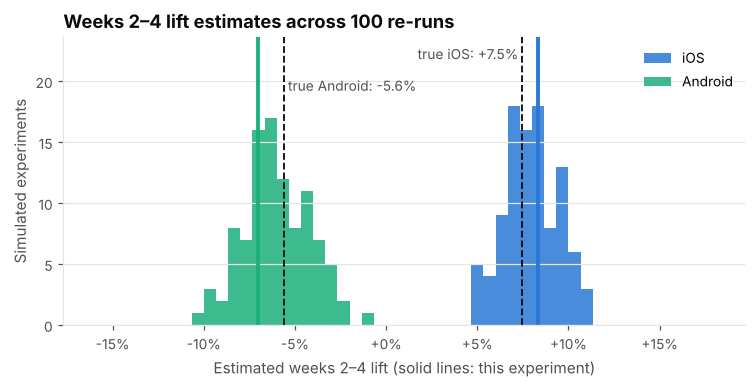

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.linspace(-0.16, 0.18, 52)
ax.hist(sims["iOS lift"], bins=bins, color=plots.CONTROL, alpha=0.85, label="iOS")
ax.hist(sims["Android lift"], bins=bins, color=plots.ACCENT, alpha=0.85, label="Android")
ax.set_ylim(0, ax.get_ylim()[1] * 1.25)
for plat, y in zip(PLATFORMS, [0.97, 0.86]):          # stagger the two labels
    tv = true_window_lift(plat)
    ax.axvline(tv, color=plots.TEXT, lw=1.2, ls="--")
    left = ev.loc[plat, "wk 2–4 lift"] < tv          # keep the label clear of the solid line
    ax.text(tv, ax.get_ylim()[1] * y, f" true {plat}: {tv:+.1%} ", fontsize=9, color=plots.TEXT_2,
            va="top", ha="left" if left else "right")
ax.axvline(ev.loc["iOS", "wk 2–4 lift"], color=plots.CONTROL, lw=2.5)
ax.axvline(ev.loc["Android", "wk 2–4 lift"], color=plots.ACCENT, lw=2.5)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
ax.set_xlabel("Estimated weeks 2–4 lift (solid lines: this experiment)")
ax.set_ylabel("Simulated experiments")
ax.set_title("Weeks 2–4 lift estimates across 100 re-runs")
ax.legend(loc="upper right")
plots.save(fig, "06_decision_simulation");

The naive rule ships to everyone in 99 of 100 re-runs, harming Android each time. Our rule
never ships to Android. It ships to iOS in most re-runs, and when it doesn't, the breakdown
shows why: the iOS effect itself is detected essentially every time, but the **AOV guardrail
fails by noise**. AOV has no true effect, yet at the segment level a 7-day window holds only a
few thousand orders per arm, so the lower CI bound often lands just below −2%. (In this very
experiment it happens on Android: −0.5%, lower bound −2.3%.)

That is a real lesson, not a footnote: **a non-inferiority guardrail needs power too.** We sized
the test for the primary metric only. The fix belongs in the next pre-registration: compute AOV
over the full 4 weeks, or set the margin from a power calculation for the guardrail itself.
Erring toward "don't ship" is the cheaper mistake here, but it is still a mistake.

Also don't over-read the clean Android result. This is a best case: the simulated world matches
the analysis model, and the Android harm is large relative to the noise at this sample size.
Real effects are smaller and messier. The point is the comparison: **the naive rule is wrong
almost always, and no amount of extra data fixes it**, because its error comes from measuring the
wrong thing (week-1 behaviour, averaged over segments), not from noise.

**On this repo's seed.** The main experiment uses `seed=22`. In a 40-seed scan
(`scripts/seed_scan.py`) it sits at the median for the blended weeks 2–4 effect and near it for
the primary metric, but it shows a slightly **larger-than-typical reversal** (iOS +8.3% and
Android −7.0%, vs medians of +7.7% and −6.4%). The re-runs above are the check that the decision
does not depend on that.